# Hydrogen bond comparative analysis

In [529]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load data

Two analysis methods per replicate. 4 WT replicates, 3 T419R replicates.

### WT

In [530]:
wt_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/hbonds_mda_ext.csv')
    wt_dfs.append([df_gmx, df_mda])


In [531]:
wt_dfs[0][0].columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

### T419R

In [532]:
T419R_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002.hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002.hbonds/hbonds_mda_ext.csv')
    T419R_dfs.append([df_gmx, df_mda])


## Method comparison (gmx vs mda)

Number and ratio of overlapping hydrogen bonds between methods, per replicate.

In [533]:
def method_overlap(df_list, frame_cutoff = 0):
    key_cols = ['donor', 'acceptor']
    for i in range(len(df_list)):

        gmx_filtered = df_list[i][0][key_cols][df_list[i][0]['frame%'] > frame_cutoff]
        mda_filtered = df_list[i][1][key_cols][df_list[i][1]['frame%'] > frame_cutoff]

        overlap1 = pd.merge(
            gmx_filtered,
            mda_filtered,
            how='inner'
        )

        total_bonds = gmx_filtered.shape[0] + mda_filtered.shape[0]
        ratio = len(overlap1) / total_bonds

        print(f"Replicate {i}")
        print(f"Number of overlapping hydrogen bonds: {len(overlap1)} out of {total_bonds}. Ratio: {ratio}")

In [534]:
method_overlap(wt_dfs)

Replicate 0
Number of overlapping hydrogen bonds: 294 out of 403. Ratio: 0.7295285359801489
Replicate 1
Number of overlapping hydrogen bonds: 396 out of 470. Ratio: 0.8425531914893617
Replicate 2
Number of overlapping hydrogen bonds: 391 out of 457. Ratio: 0.8555798687089715


In [535]:
method_overlap(T419R_dfs)

Replicate 0
Number of overlapping hydrogen bonds: 320 out of 422. Ratio: 0.7582938388625592
Replicate 1
Number of overlapping hydrogen bonds: 395 out of 446. Ratio: 0.8856502242152466
Replicate 2
Number of overlapping hydrogen bonds: 325 out of 410. Ratio: 0.7926829268292683


Same overlap analysis, filtering out hydrogen bonds identified in < 10 \% of the frames.

In [536]:
method_overlap(wt_dfs, 10)

Replicate 0
Number of overlapping hydrogen bonds: 50 out of 88. Ratio: 0.5681818181818182
Replicate 1
Number of overlapping hydrogen bonds: 38 out of 60. Ratio: 0.6333333333333333
Replicate 2
Number of overlapping hydrogen bonds: 42 out of 68. Ratio: 0.6176470588235294


In [537]:
method_overlap(T419R_dfs, 10)

Replicate 0
Number of overlapping hydrogen bonds: 66 out of 92. Ratio: 0.717391304347826
Replicate 1
Number of overlapping hydrogen bonds: 45 out of 83. Ratio: 0.5421686746987951
Replicate 2
Number of overlapping hydrogen bonds: 57 out of 90. Ratio: 0.6333333333333333


Plot overlap number.

In [538]:
wt_dfs_flat =  [x for xs in wt_dfs for x in xs]
T419R_dfs_flat =  [x for xs in T419R_dfs for x in xs]
df_all = pd.concat(wt_dfs_flat + T419R_dfs_flat)

In [539]:
len(wt_dfs_flat)

6

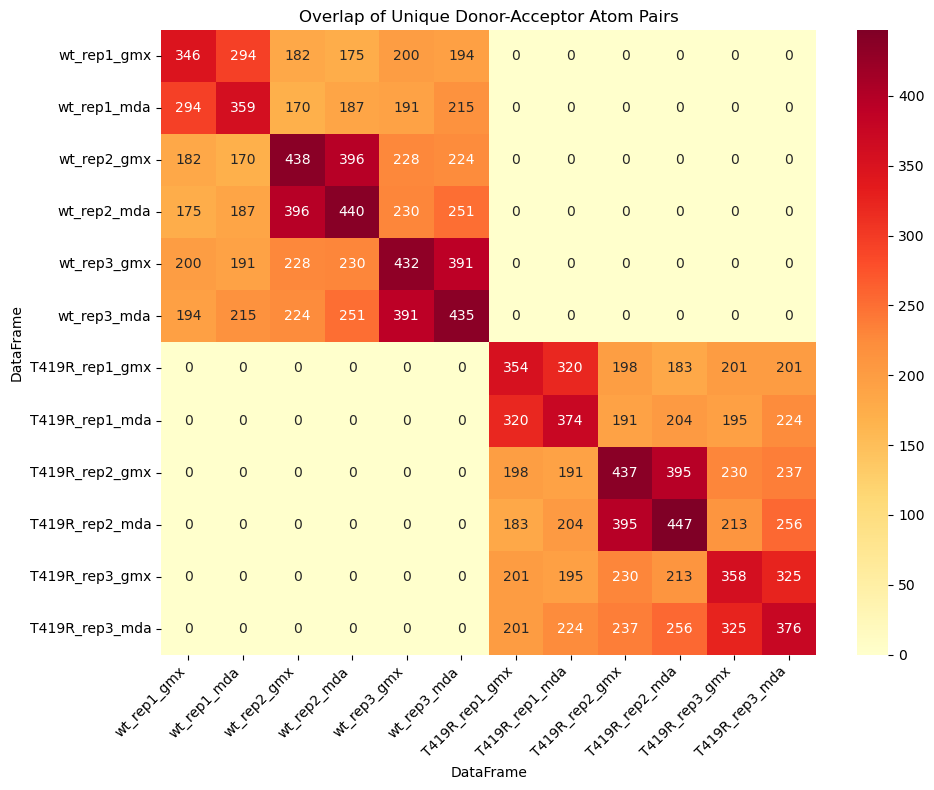

In [541]:
# Combine WT and T419R DataFrames
all_dfs_flat = wt_dfs_flat + T419R_dfs_flat

# Key columns for triplets
key_cols = ['donor', 'acceptor']

# Labels for DataFrames
labels = ['wt_rep1_gmx', 'wt_rep1_mda', 
          'wt_rep2_gmx', 'wt_rep2_mda', 'wt_rep3_gmx', 'wt_rep3_mda',
          'T419R_rep1_gmx', 'T419R_rep1_mda', 
          'T419R_rep2_gmx', 'T419R_rep2_mda', 'T419R_rep3_gmx', 'T419R_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols]
        df2_triplets = all_dfs_flat[j][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Verify that there are no common donor-acceptor atom pairs identified between WT and T419R.

In [542]:
# Key columns
key_cols = ['donor', 'acceptor']

# Aggregate unique triplets from wt_dfs_flat
wt_triplets = pd.concat([df[key_cols] for df in wt_dfs_flat], ignore_index=True).drop_duplicates()

# Aggregate unique triplets from T419R_dfs_flat
T419R_triplets = pd.concat([df[key_cols] for df in T419R_dfs_flat], ignore_index=True).drop_duplicates()

# Find overlapping triplets
overlap = pd.merge(wt_triplets, T419R_triplets, how='inner', on=key_cols)

# Report results
if overlap.empty:
    print("No common ['donor', 'hydrogen', 'acceptor'] triplets between WT and T419R DataFrames.")
else:
    print(f"Found {len(overlap)} common triplets:")
    print(overlap)

# Optional: Show number of unique triplets in each group
print(f"Unique WT triplets: {len(wt_triplets)}")
print(f"Unique T419R triplets: {len(T419R_triplets)}")

No common ['donor', 'hydrogen', 'acceptor'] triplets between WT and T419R DataFrames.
Unique WT triplets: 339
Unique T419R triplets: 344


For a less stringent comparison, consider the donor and acceptor residue numbers instead of specific atoms.

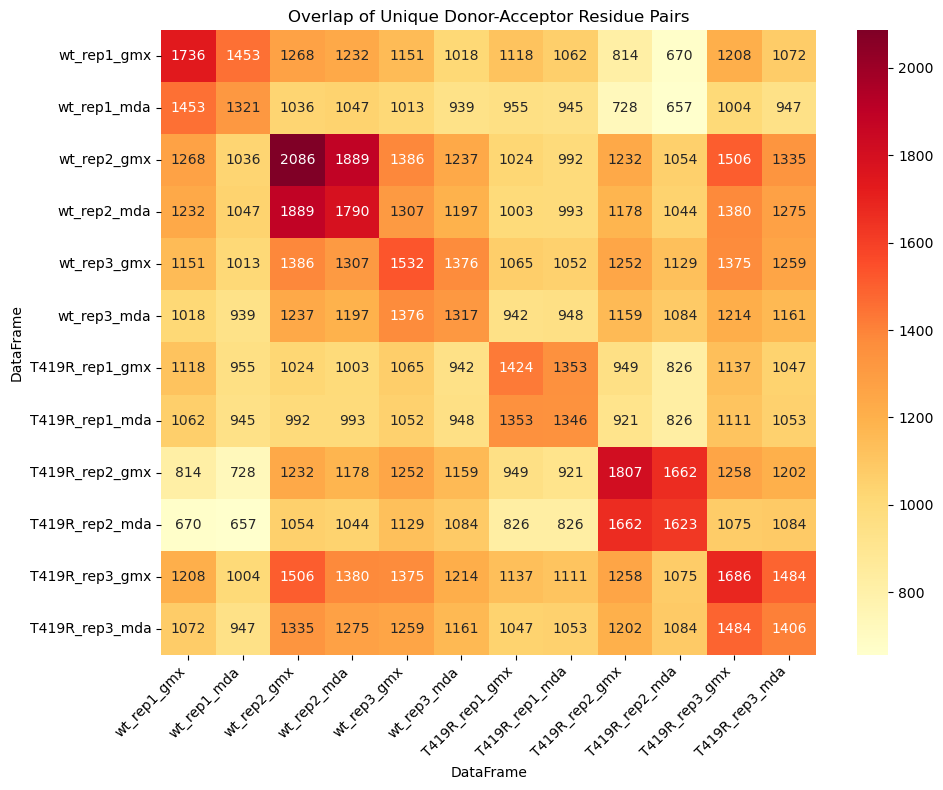

In [543]:
# Combine WT and T419R DataFrames
all_dfs_flat = wt_dfs_flat + T419R_dfs_flat

# Key columns for triplets
key_cols = ['donor_res_num', 'acceptor_res_num']

# Labels for DataFrames
labels = ['wt_rep1_gmx', 'wt_rep1_mda', 
          'wt_rep2_gmx', 'wt_rep2_mda', 'wt_rep3_gmx', 'wt_rep3_mda',
          'T419R_rep1_gmx', 'T419R_rep1_mda', 
          'T419R_rep2_gmx', 'T419R_rep2_mda', 'T419R_rep3_gmx', 'T419R_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df2_triplets = all_dfs_flat[j][key_cols]
        df1_triplets = all_dfs_flat[i][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Plot overlap ratios.

[50, 54, 53, 57, 60, 64, 56, 57, 54, 52, 53, 53]


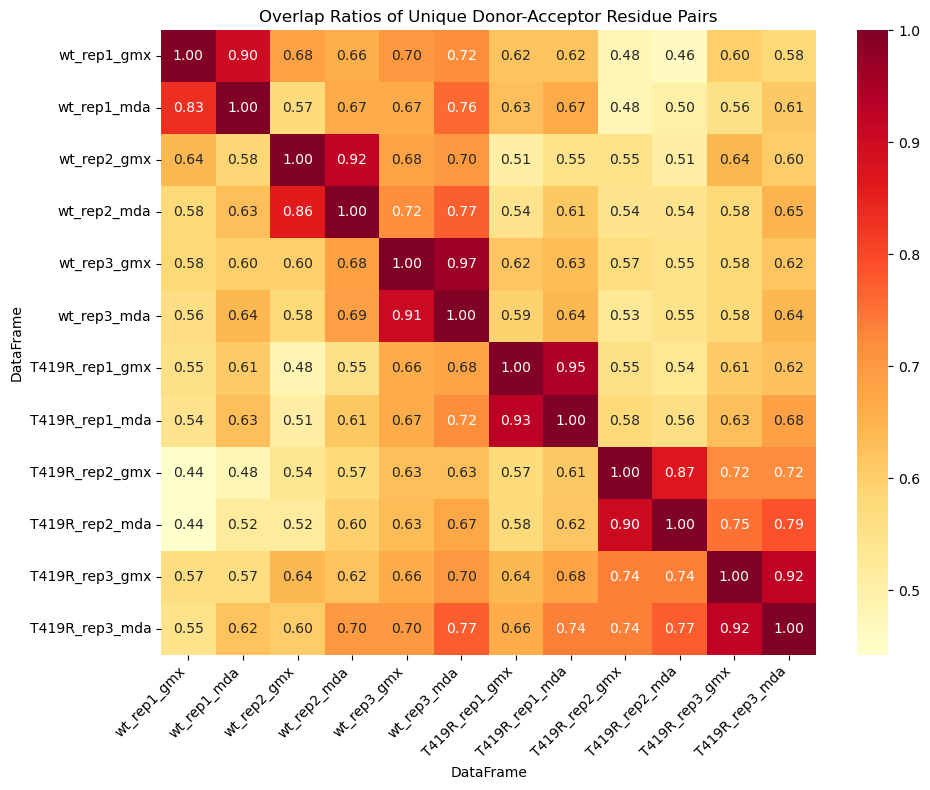

In [544]:
key_cols = ['donor_res_num', 'acceptor_res_num']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

[149, 134, 159, 154, 155, 147, 157, 151, 150, 136, 150, 138]


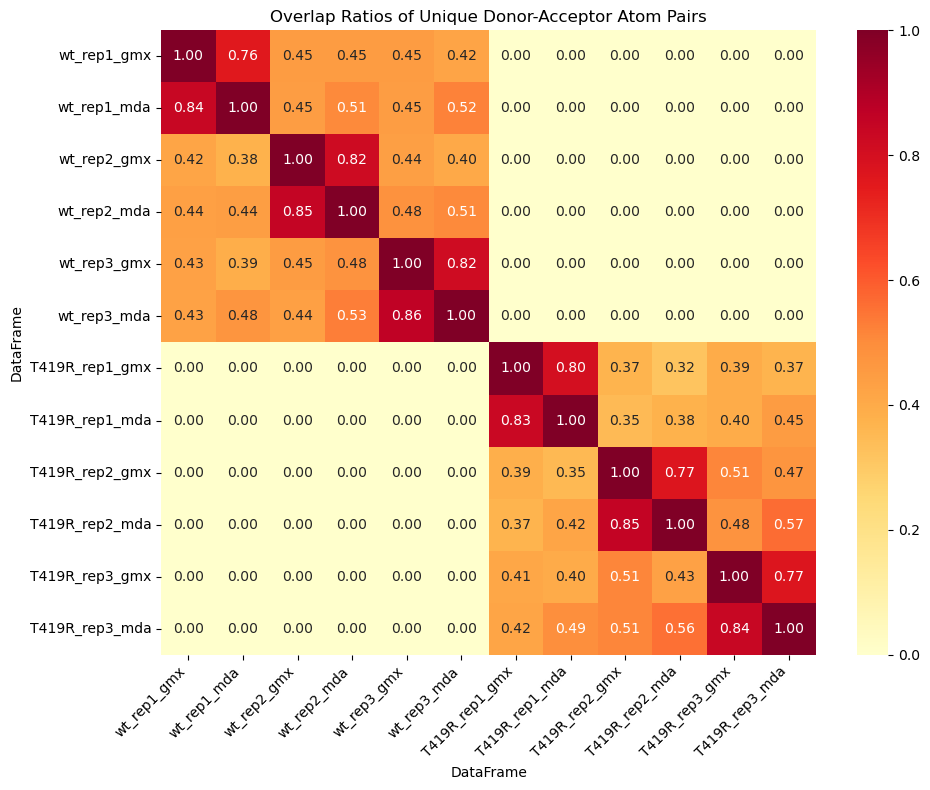

In [545]:
key_cols = ['donor', 'acceptor']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

## Bond distribution

In [546]:
combined_df_wt = pd.concat(wt_dfs_flat)

In [547]:
combined_df_wt.columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [548]:
combined_df_wt["donor_type"].value_counts()

donor_type
protein    1290
DNA          40
Name: count, dtype: int64

In [549]:
print(combined_df_wt[combined_df_wt["donor_type"] == "protein"]["frame%"].mean())
print(combined_df_wt[combined_df_wt["donor_type"] == "DNA"]["frame%"].mean())

7.381533195486684
0.9965034965034965


As expected, the protein (amino acids) acts as donor in the majority of identified hydrogen bonds and the average number of frames in which these bonds are identified is higher, indicating the positions that lead to them are more stable in time. Therefore, the analysis focuses on the protein as donor and DNA as acceptor in hydrogen bonds.

### WT

Find unique pairs of donor-acceptor atoms and sum their counts across replicates and methods. The hydrogen atom number is not taken into account to consider it as the "same bond".

In [550]:
group_columns = combined_df_wt.columns.difference(["frame%", "count", "hydrogen"])
wt_count = combined_df_wt.groupby(list(group_columns))['count'].sum().reset_index()

wt_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
40,19049,OP2,C,DT,8,8,backbone,DNA,5365,OG,A,SER,324,459,DBD,protein,4800
37,19048,OP1,C,DT,8,8,backbone,DNA,4104,NH1,A,ARG,243,378,DBD,protein,4438
226,19827,O4,D,DT,9,9,base,DNA,14791,ND2,B,ASN,325,460,DBD,protein,2800
69,19172,OP1,C,DC,12,12,backbone,DNA,12629,OG1,B,THR,192,327,DBD,protein,2710
30,19016,OP1,C,DT,7,7,backbone,DNA,4874,OG1,A,THR,292,427,DBD,protein,2690


In [551]:
wt_count.shape

(339, 17)

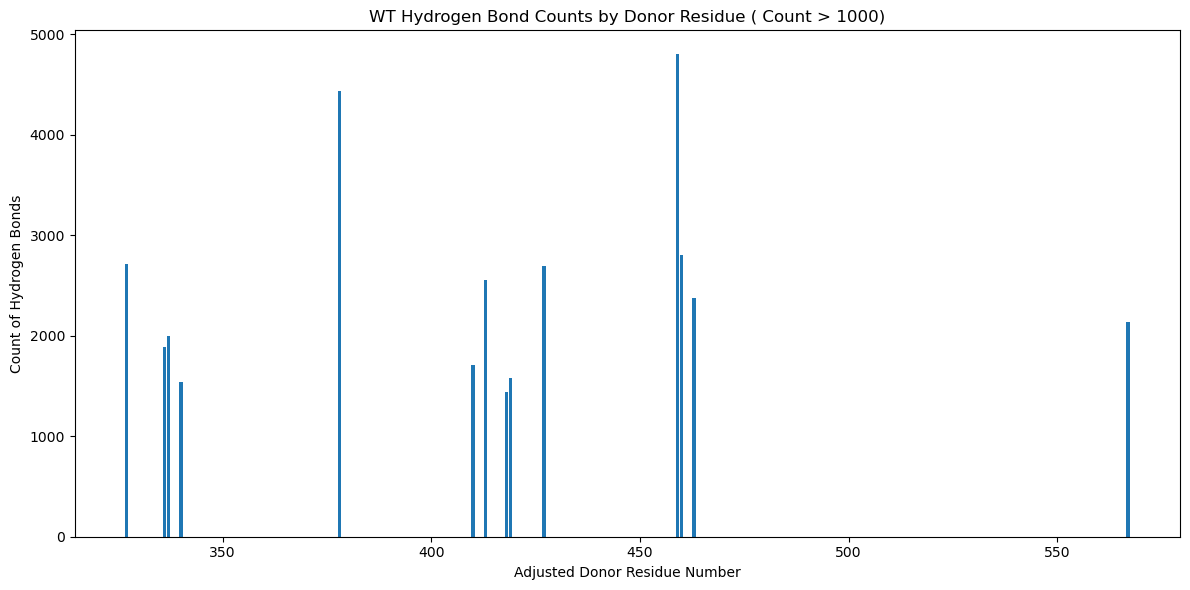

In [552]:
filtered_df = wt_count[wt_count['count'] > 1000]

plt.figure(figsize=(12, 6))
plt.bar(filtered_df['donor_res_num_adjusted'], filtered_df['count'])
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Donor Residue ( Count > 1000)')
plt.tight_layout()

# Show the plot
plt.show()

Comparison between monomers A and B.

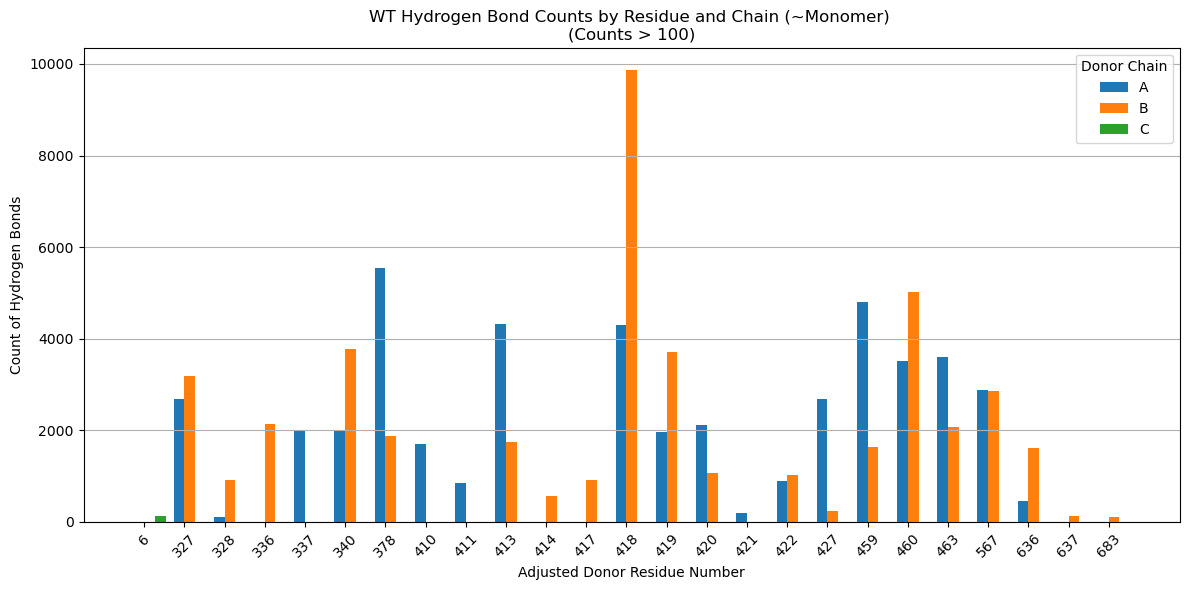

In [553]:
filtered_df = wt_count[wt_count['count'] > 100]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Chain (~Monomer) \n(Counts > 100)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

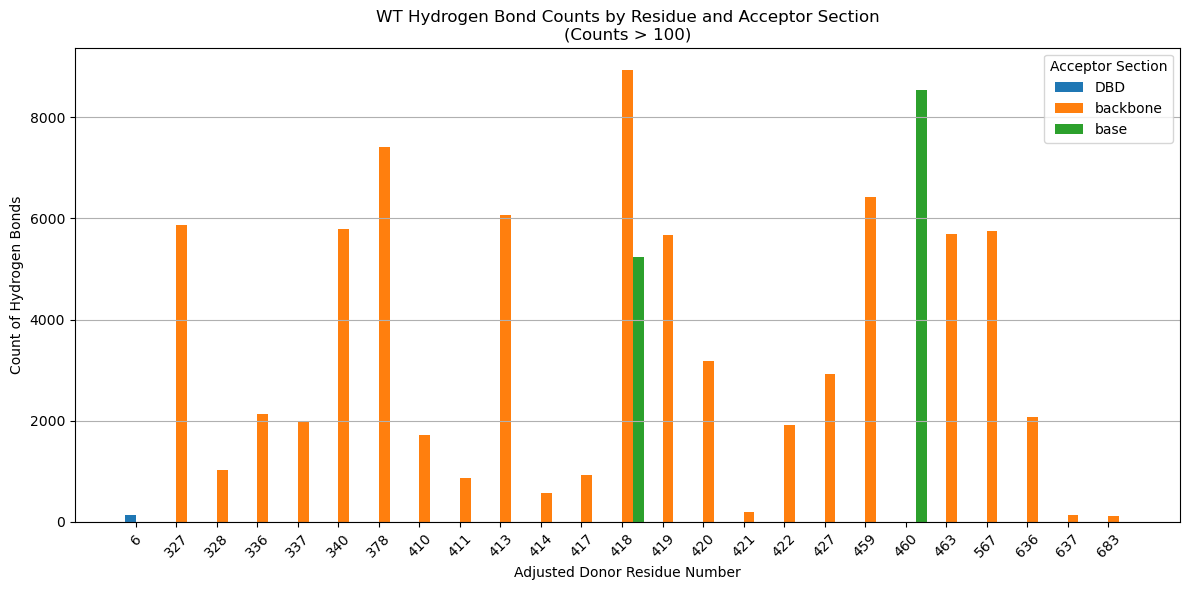

In [554]:
filtered_df = wt_count[wt_count['count'] > 100]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Acceptor Section\n(Counts > 100)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

#### Summary tables
For e replicates and 2 methods, a threshold of count > 600 is equivalent to > 10%.

In [555]:
occ_th = 100 * len(wt_dfs) * len(wt_dfs[0])
occ_th

600

In [556]:
total_frames_wt = 1000 * len(wt_dfs) * len(wt_dfs[0])
total_frames_wt

6000

**Monomer A**

In [557]:
wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)].shape

(20, 17)

In [558]:
summary_cols = wt_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
40,OP2,C,DT,8,backbone,4800,OG,SER,459,DBD
37,OP1,C,DT,8,backbone,4438,NH1,ARG,378,DBD
30,OP1,C,DT,7,backbone,2690,OG1,THR,427,DBD
47,OP1,C,DT,9,backbone,2560,NZ,LYS,413,DBD
41,OP2,C,DT,8,backbone,2375,NE2,GLN,463,DBD
48,OP2,C,DT,9,backbone,1999,OG1,THR,337,DBD
245,OP2,D,DG,12,backbone,1930,OG1,THR,327,DBD
52,O4,C,DT,9,base,1810,ND2,ASN,460,DBD
252,OP1,D,DG,13,backbone,1788,NZ,LYS,567,LD
45,OP1,C,DT,9,backbone,1712,NZ,LYS,410,DBD


In [559]:
wt_monoA_summary = wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)][summary_cols]
wt_monoA_summary['occupancy'] = round(wt_monoA_summary['count'] / total_frames_wt, 2)
wt_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
40,OP2,C,DT,8,backbone,4800,OG,SER,459,DBD,0.80
37,OP1,C,DT,8,backbone,4438,NH1,ARG,378,DBD,0.74
30,OP1,C,DT,7,backbone,2690,OG1,THR,427,DBD,0.45
47,OP1,C,DT,9,backbone,2560,NZ,LYS,413,DBD,0.43
41,OP2,C,DT,8,backbone,2375,NE2,GLN,463,DBD,0.40


**Monomer B**

In [560]:
wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)].shape

(26, 17)

In [561]:
summary_cols = wt_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
226,O4,D,DT,9,base,2800,ND2,ASN,460,DBD
69,OP1,C,DC,12,backbone,2710,OG1,THR,327,DBD
77,OP1,C,DG,13,backbone,2140,NZ,LYS,567,LD
74,OP2,C,DC,12,backbone,1893,NZ,LYS,336,DBD
212,OP2,D,DT,8,backbone,1817,NE2,GLN,463,DBD
211,OP2,D,DT,8,backbone,1633,OG,SER,459,DBD
138,OP1,C,DA,21,backbone,1576,OG1,THR,419,DBD
104,O2,C,DT,18,base,1439,NH1,ARG,418,DBD
162,N3,D,DA,6,base,1381,NH1,ARG,418,DBD
105,O2,C,DT,18,base,1332,NH2,ARG,418,DBD


In [562]:
wt_monoB_summary = wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)][summary_cols]
wt_monoB_summary['occupancy'] = round(wt_monoB_summary['count'] / total_frames_wt, 2)
wt_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
226,O4,D,DT,9,base,2800,ND2,ASN,460,DBD,0.47
69,OP1,C,DC,12,backbone,2710,OG1,THR,327,DBD,0.45
77,OP1,C,DG,13,backbone,2140,NZ,LYS,567,LD,0.36
74,OP2,C,DC,12,backbone,1893,NZ,LYS,336,DBD,0.32
212,OP2,D,DT,8,backbone,1817,NE2,GLN,463,DBD,0.30


In [563]:
wt_summary = pd.concat([wt_monoA_summary, wt_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [564]:
wt_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 28                 O4'              C                DG   
          30                 OP1              C                DT   
          32                 OP2              C                DT   
          37                 OP1              C                DT   
          38                 OP2              C                DT   
          40                 OP2              C                DT   
          41                 OP2              C                DT   
          44                 O3'              C                DT   
          45                 OP1              C                DT   
          47                 OP1              C                DT   
          48                 OP2              C                DT   
          50                 OP2              C                DT   
          52                  O4              C                DT   
          236                OP1              D                DC   
          245                OP2              D                DG   
          252                OP1              D                DG   
          254                OP2              D                DG   
          266                 O6              D                DG   
          296                OP1              D                DG   
          320                O3'              D                DG   
Monomer B 62                 OP1              C                DC   
          63                 OP1              C                DC   
          64                 OP2              C                DC   
          69                 OP1              C                DC   
          74                 OP2              C                DC   
          77                 OP1              C                DG   
          87                 OP1              C                DG   
          90                 OP2              C                DG   
          93                  N7              C                DG   
          94                  O6              C                DG   
          104                 O2              C                DT   
          105                 O2              C                DT   
          138                OP1              C                DA   
          162                 N3              D                DA   
          167                OP1              D                DT   
          168                OP1              D                DT   
          169                OP1              D                DT   
          170                OP1              D                DT   
          172                OP1              D                DT   
          200                OP1              D                DT   
          201                OP1              D                DT   
          211                OP2              D                DT   
          212                OP2              D                DT   
          219                 O4              D                DT   
          222                OP1              D                DT   
          226                 O4              D                DT   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 28                           6         backbone    630   
          30                           7         backbone   2690   
          32                           7         backbone   1238   
          37                           8         backbone   4438   
          38                           8         backbone   1114   
          40                           8         backbone   4800   
          41                           8         backbone   2375   
          44                           8         backbone   1303   
          45                           9         backbone   1712   
          47                           9         backbone   2560   
          48          

In [642]:
wt_summary.to_csv('wt_summary.csv')

### T419R

Find unique pairs of donor-acceptor atoms and sum their counts across replicates and methods. The hydrogen atom number is not taken into account to consider it as the "same bond".

In [566]:
combined_df_T419R = pd.concat(T419R_dfs_flat)

In [567]:
group_columns = combined_df_T419R.columns.difference(["frame%", "count", "hydrogen"])
T419R_count = combined_df_T419R.groupby(list(group_columns))['count'].sum().reset_index()

T419R_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
238,19847,O4,D,DT,9,9,base,DNA,14811,ND2,B,ASN,325,460,DBD,protein,4966
213,19796,OP2,D,DT,8,8,backbone,DNA,14855,NE2,B,GLN,328,463,DBD,protein,4537
212,19796,OP2,D,DT,8,8,backbone,DNA,14798,OG,B,SER,324,459,DBD,protein,4442
84,19193,OP2,C,DC,12,12,backbone,DNA,12799,NZ,B,LYS,201,336,DBD,protein,4338
80,19192,OP1,C,DC,12,12,backbone,DNA,12639,OG1,B,THR,192,327,DBD,protein,3998


In [568]:
T419R_count.shape

(344, 17)

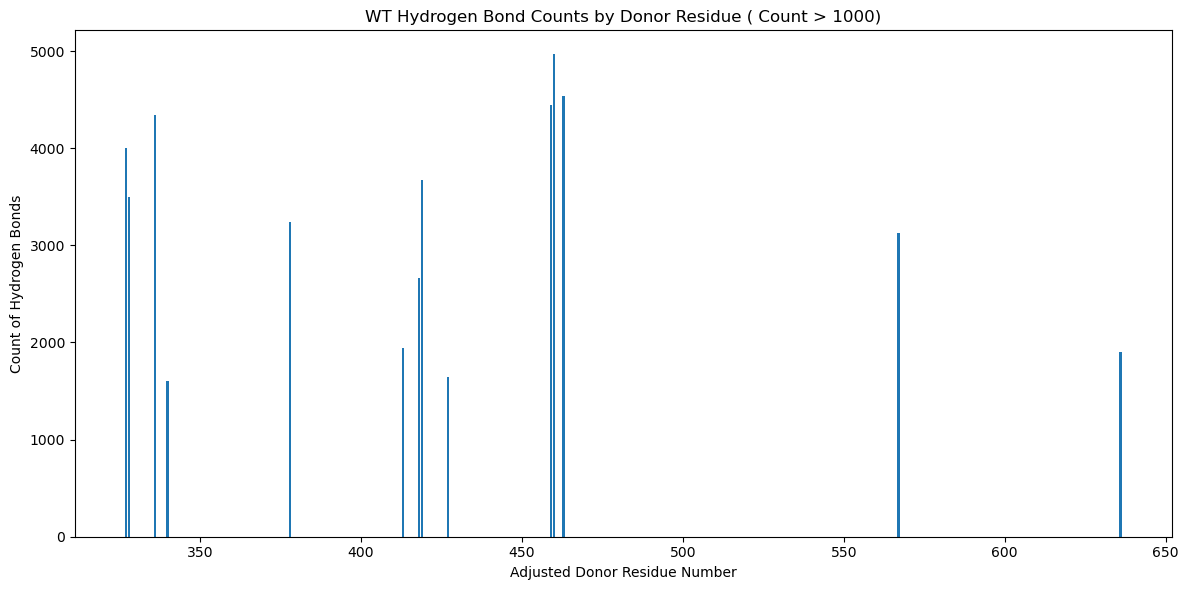

In [569]:
filtered_df = T419R_count[T419R_count['count'] > 1000]

plt.figure(figsize=(12, 6))
plt.bar(filtered_df['donor_res_num_adjusted'], filtered_df['count'])
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Donor Residue ( Count > 1000)')
plt.tight_layout()

# Show the plot
plt.show()

Comparison between monomers A and B.

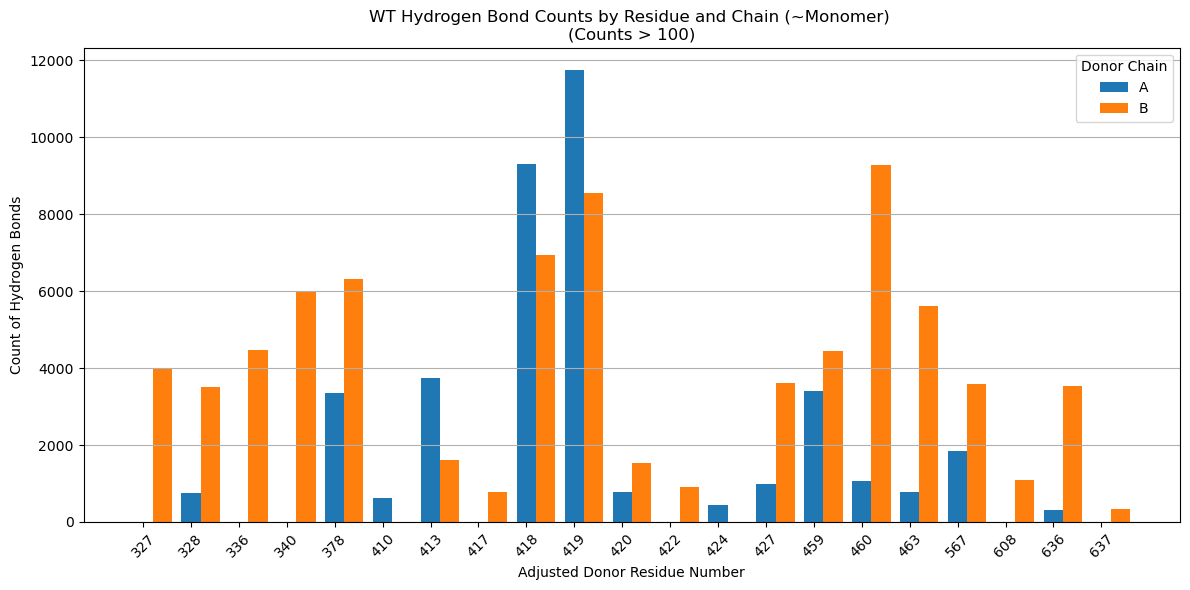

In [570]:
filtered_df = T419R_count[T419R_count['count'] > 100]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Chain (~Monomer) \n(Counts > 100)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

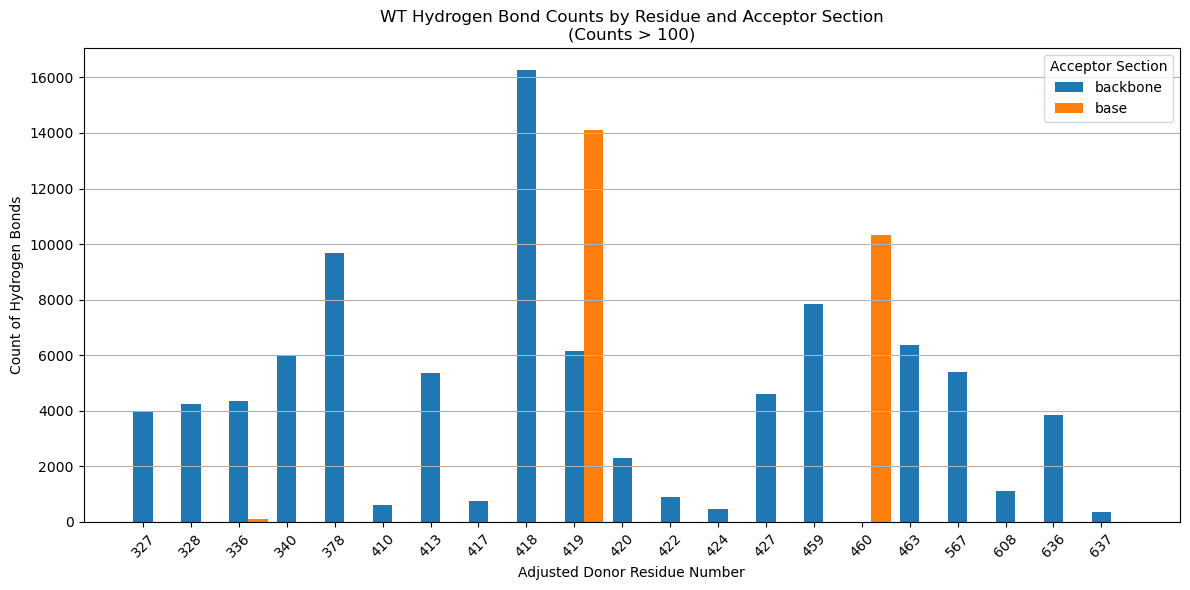

In [571]:
filtered_df = T419R_count[T419R_count['count'] > 100]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Acceptor Section\n(Counts > 100)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

#### Summary tables
For 4 replicates and 2 methods, a threshold of count > 800 is equivalent to > 10%.

In [572]:
occ_th = 100 * len(wt_dfs) * len(wt_dfs[0])
occ_th

600

In [573]:
total_frames_T419R = 1000 * len(T419R_dfs) * len(T419R_dfs[0])
total_frames_T419R

6000

**Monomer A**

In [574]:
T419R_count[(T419R_count['donor_chain'] == 'A') & (T419R_count["count"] > occ_th)].shape

(21, 17)

In [575]:
summary_cols = T419R_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
T419R_count[(T419R_count['donor_chain'] == 'A') & (T419R_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
293,O2,D,DT,19,base,3674,NH2,ARG,419,DBD
58,OP2,C,DT,8,backbone,3401,OG,SER,459,DBD
297,OP1,D,DG,20,backbone,2662,NE,ARG,418,DBD
292,O2,D,DT,19,base,2239,NH1,ARG,419,DBD
56,OP2,C,DT,8,backbone,2216,NH1,ARG,378,DBD
299,OP1,D,DG,20,backbone,1994,NH2,ARG,418,DBD
66,OP1,C,DT,9,backbone,1947,NZ,LYS,413,DBD
260,OP1,D,DG,13,backbone,1207,NZ,LYS,567,LD
304,OP2,D,DG,20,backbone,1100,NH2,ARG,418,DBD
314,N3,D,DG,20,base,1040,NH1,ARG,419,DBD


In [576]:
T419R_monoA_summary = T419R_count[(T419R_count['donor_chain'] == 'A') & (T419R_count["count"] > occ_th)][summary_cols]
T419R_monoA_summary['occupancy'] = round(T419R_monoA_summary['count'] / total_frames_T419R, 2)
T419R_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
293,O2,D,DT,19,base,3674,NH2,ARG,419,DBD,0.61
58,OP2,C,DT,8,backbone,3401,OG,SER,459,DBD,0.57
297,OP1,D,DG,20,backbone,2662,NE,ARG,418,DBD,0.44
56,OP2,C,DT,8,backbone,2216,NH1,ARG,378,DBD,0.37
292,O2,D,DT,19,base,2239,NH1,ARG,419,DBD,0.37


**Monomer B**

In [577]:
T419R_count[(T419R_count['donor_chain'] == 'B') & (T419R_count["count"] > occ_th)].shape

(32, 17)

In [578]:
summary_cols = T419R_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
T419R_count[(T419R_count['donor_chain'] == 'B') & (T419R_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
238,O4,D,DT,9,base,4966,ND2,ASN,460,DBD
213,OP2,D,DT,8,backbone,4537,NE2,GLN,463,DBD
212,OP2,D,DT,8,backbone,4442,OG,SER,459,DBD
84,OP2,C,DC,12,backbone,4338,NZ,LYS,336,DBD
80,OP1,C,DC,12,backbone,3998,OG1,THR,327,DBD
81,OP1,C,DC,12,backbone,3497,NE2,HIE,328,DBD
202,OP1,D,DT,8,backbone,3236,NH1,ARG,378,DBD
103,O6,C,DG,14,base,3133,ND2,ASN,460,DBD
88,OP1,C,DG,13,backbone,3125,NZ,LYS,567,LD
115,O2,C,DT,18,base,2776,NH2,ARG,419,DBD


In [579]:
T419R_monoB_summary = T419R_count[(T419R_count['donor_chain'] == 'B') & (T419R_count["count"] > occ_th)][summary_cols]
T419R_monoB_summary['occupancy'] = round(T419R_monoB_summary['count'] / total_frames_T419R, 2)
T419R_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
238,O4,D,DT,9,base,4966,ND2,ASN,460,DBD,0.83
213,OP2,D,DT,8,backbone,4537,NE2,GLN,463,DBD,0.76
212,OP2,D,DT,8,backbone,4442,OG,SER,459,DBD,0.74
84,OP2,C,DC,12,backbone,4338,NZ,LYS,336,DBD,0.72
80,OP1,C,DC,12,backbone,3998,OG1,THR,327,DBD,0.67


In [580]:
T419R_summary = pd.concat([T419R_monoA_summary, T419R_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [581]:
T419R_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 12                  N3              C                DA   
          24                 O3'              C                DG   
          32                 OP1              C                DT   
          37                 OP1              C                DT   
          56                 OP2              C                DT   
          57                 OP2              C                DT   
          58                 OP2              C                DT   
          66                 OP1              C                DT   
          67                 OP2              C                DT   
          69                  O4              C                DT   
          260                OP1              D                DG   
          288                OP1              D                DT   
          292                 O2              D                DT   
          293                 O2              D                DT   
          297                OP1              D                DG   
          299                OP1              D                DG   
          304                OP2              D                DG   
          309                O4'              D                DG   
          314                 N3              D                DG   
          320                OP1              D                DT   
          329                OP2              D                DT   
Monomer B 74                 OP1              C                DC   
          75                 OP1              C                DC   
          76                 OP2              C                DC   
          80                 OP1              C                DC   
          81                 OP1              C                DC   
          84                 OP2              C                DC   
          88                 OP1              C                DG   
          95                 OP1              C                DG   
          98                 OP2              C                DG   
          102                 N7              C                DG   
          103                 O6              C                DG   
          114                 O2              C                DT   
          115                 O2              C                DT   
          140                OP1              C                DC   
          145                OP1              C                DC   
          147                OP2              C                DC   
          149                OP2              C                DC   
          160                OP1              C                DA   
          162                OP2              C                DA   
          163                OP2              C                DA   
          186                OP1              D                DT   
          189                OP2              D                DT   
          190                OP2              D                DT   
          202                OP1              D                DT   
          208                OP1              D                DT   
          209                OP2              D                DT   
          210                OP2              D                DT   
          212                OP2              D                DT   
          213                OP2              D                DT   
          226                OP1              D                DT   
          229                OP1              D                DT   
          238                 O4              D                DT   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 12                           5             base    741   
          24                           6         backbone    982   
          32                           7         backbone    996   
          37   

In [582]:
T419R_summary.sort_values("donor_res_num_adjusted").to_csv('T419R_summary.csv')

## Comparison T419R vs WT

### Protein as donor

**Frame %**

The two following plots are not normalized to account for one more replicate for WT than T419R, making the difference in the number of hydrogen bonds with residue 419 as the donor even more striking.

Text(0.5, 1.0, 'WT 419 Hydrogen Bond Frame % Distribution')

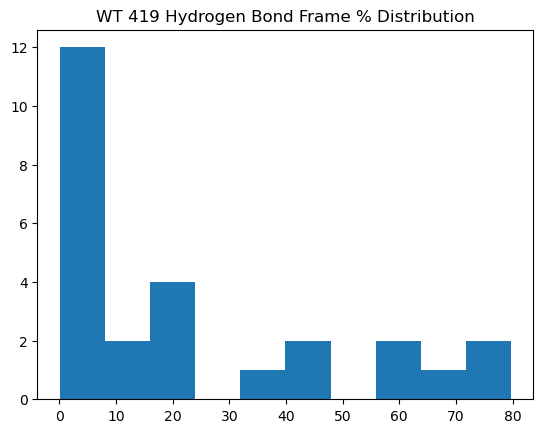

In [583]:
filtered_df = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]
plt.hist(filtered_df['frame%'])
plt.title('WT 419 Hydrogen Bond Frame % Distribution')

Text(0.5, 1.0, 'T419R 419 Hydrogen Bond Frame % Distribution')

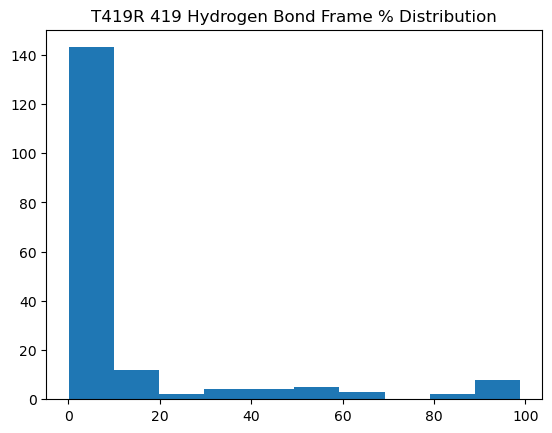

In [584]:
filtered_df = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
plt.hist(filtered_df['frame%'])
plt.title('T419R 419 Hydrogen Bond Frame % Distribution')

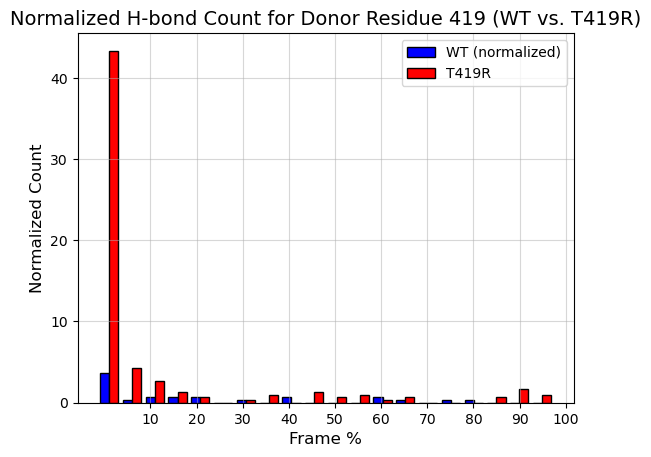

In [588]:
# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize counts by the number of replicates
normalized_wt_counts = wt_counts / len(wt_dfs)
normalized_mut_counts = mut_counts / len(T419R_dfs)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
plt.bar(mut_positions, normalized_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for Donor Residue 419 (WT vs. T419R)', fontsize=14)  # Updated title
plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [589]:
filtered_df_T419R.shape

(183, 19)

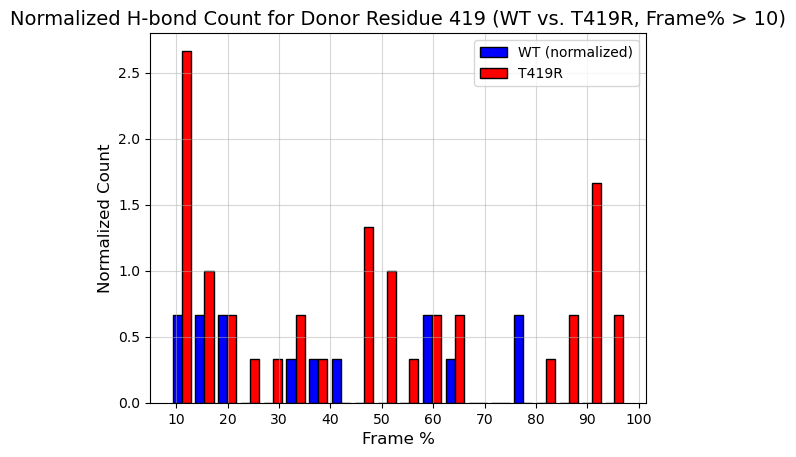

In [590]:
# Filter data for frame% > 10
filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)]
filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == 419) & (combined_df_wt['frame%'] > 10)]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize counts by the number of replicates
normalized_wt_counts = wt_counts / len(wt_dfs)
normalized_mut_counts = mut_counts / len(T419R_dfs)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
plt.bar(mut_positions, normalized_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for Donor Residue 419 (WT vs. T419R, Frame% > 10)', fontsize=14)  # Updated title
plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [591]:
filtered_df_T419R.shape

(40, 19)

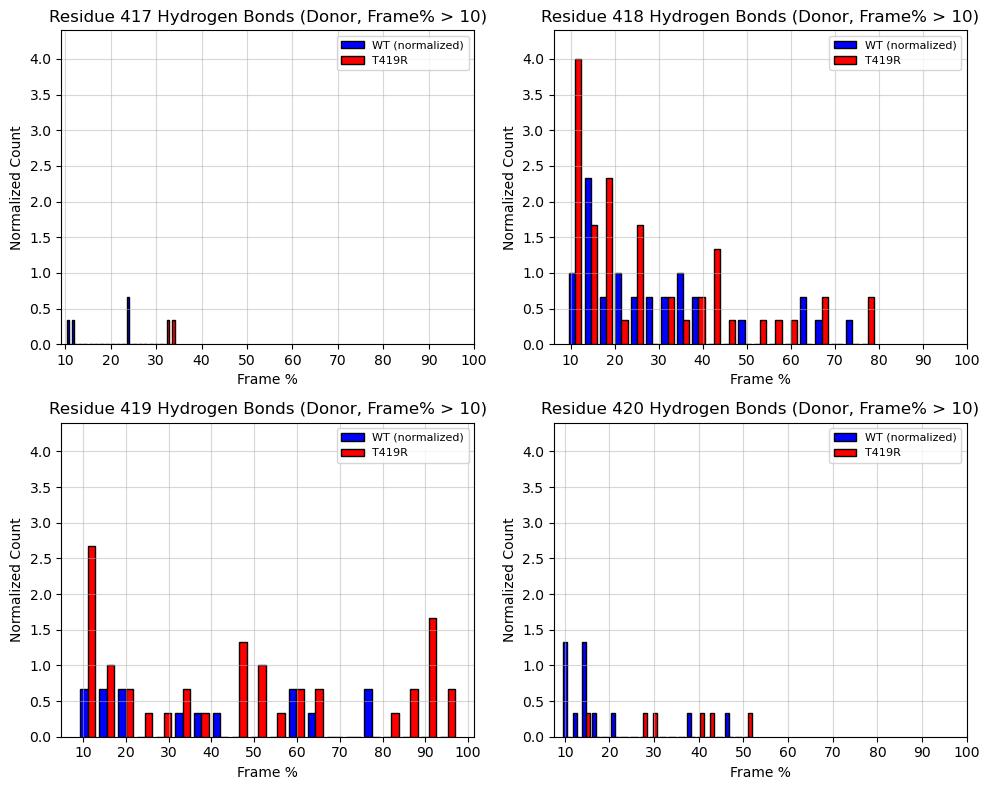

In [616]:

# Residues to plot
residues = [417, 418, 419, 420]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == residue) & (combined_df_T419R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    # Common bins
    bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T419R['frame%'], bins=bins)

    # Normalize counts by the number of replicates
    normalized_wt_counts = wt_counts / len(wt_dfs)
    normalized_mut_counts = mut_counts / len(T419R_dfs)

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(normalized_wt_counts), max(normalized_mut_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == residue) & (combined_df_T419R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    # Common bins
    bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T419R['frame%'], bins=bins)

    # Normalize counts by the number of replicates
    normalized_wt_counts = wt_counts / len(wt_dfs)
    normalized_mut_counts = mut_counts / len(T419R_dfs)

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    wt_positions = bins[:-1]
    mut_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
    axes[i].bar(mut_positions, normalized_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Normalized Count', fontsize=10)
    axes[i].set_title(f'Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 6 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

Bonds where residue 419 is the donor and frame % > 10.

In [593]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)].shape

(40, 19)

In [594]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)].sort_values('frame%', ascending=False).head(10)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
156,14169,14170,19449,989,98.801199,ARG,284,N,B,DC,20,OP1,C,protein,DNA,419,20,DBD,backbone
52,4765,4767,20168,972,97.102897,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
56,4765,4767,20168,944,94.305694,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
151,14185,14187,19408,924,92.307692,ARG,284,NH1,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
53,4765,4766,20184,920,91.908092,ARG,284,NH2,A,DG,20,O4',D,protein,DNA,419,20,DBD,backbone
58,4765,4767,20168,913,91.208791,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
49,4762,4763,20168,910,90.909091,ARG,284,NH1,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
162,14188,14190,19408,895,89.410589,ARG,284,NH2,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
151,14185,14187,19408,878,87.712288,ARG,284,NH1,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
61,4765,4767,20168,845,84.415584,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base


Acceptor residue sections. Are the hydrogen bonds happening with the DNA backbone or the bases?

In [618]:
def process_residue_data(residue, df, replicates):
    filtered_df = df[(df['donor_res_num_adjusted'] == residue) & (df['frame%'] > 10)]
    base = filtered_df[filtered_df['acceptor_section'] == 'base']
    backbone = filtered_df[filtered_df['acceptor_section'] == 'backbone']
    bins = np.histogram(np.hstack((base['frame%'], backbone['frame%'])), bins=20)[1]
    base_counts, _ = np.histogram(base['frame%'], bins=bins)
    backbone_counts, _ = np.histogram(backbone['frame%'], bins=bins)
    norm_base = base_counts / replicates
    norm_backbone = backbone_counts / replicates
    return norm_base, norm_backbone, bins

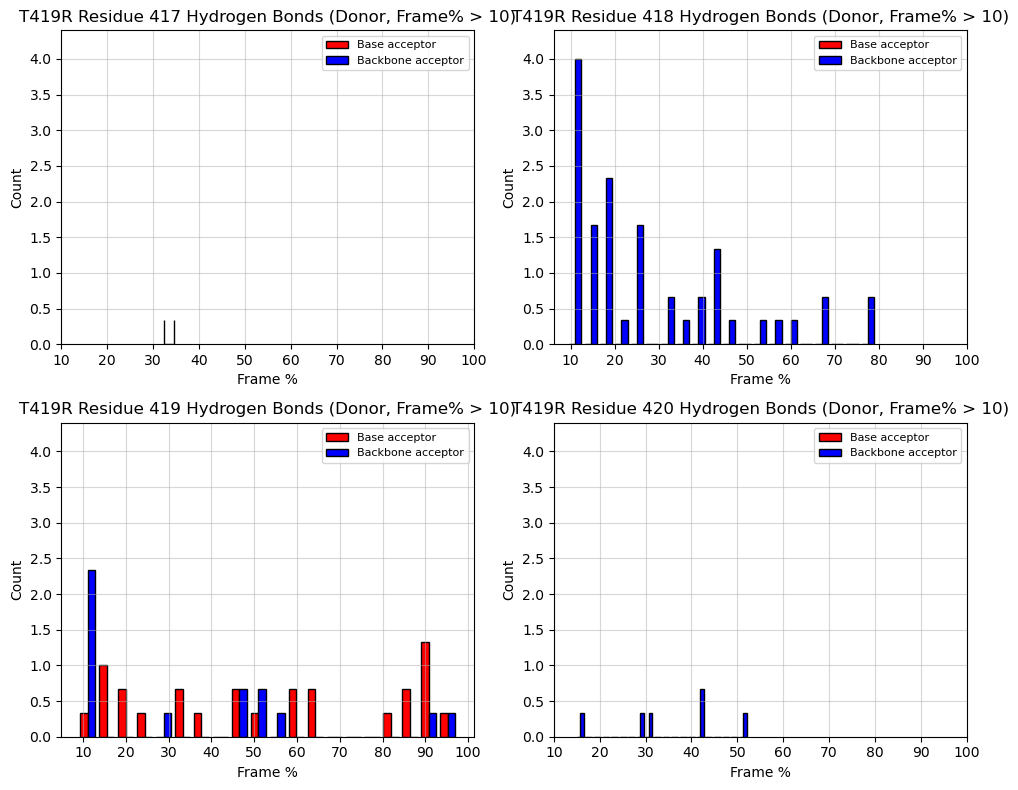

In [621]:
residues = [417, 418, 419, 420]
max_y_value = 0
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
axes = axes.flatten()

for i, residue in enumerate(residues):
    norm_base, norm_backbone, bins = process_residue_data(residue, combined_df_T419R, len(T419R_dfs))
    max_y_value = max(max_y_value, max(norm_base), max(norm_backbone))

    bar_width = (bins[1] - bins[0]) * 0.4
    axes[i].bar(bins[:-1], norm_base, width=bar_width, color='red', label='Base acceptor', edgecolor='black')
    axes[i].bar(bins[:-1] + bar_width, norm_backbone, width=bar_width, color='blue', label='Backbone acceptor', edgecolor='black')

    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)
    axes[i].set_title(f'T419R Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))
    axes[i].tick_params(axis='y', labelleft=True)
    axes[i].set_ylim(0, max_y_value * 1.1)
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**DNA residues binding to residue 419**

Note that these bonds are NOT filtered fo frame % > 10.

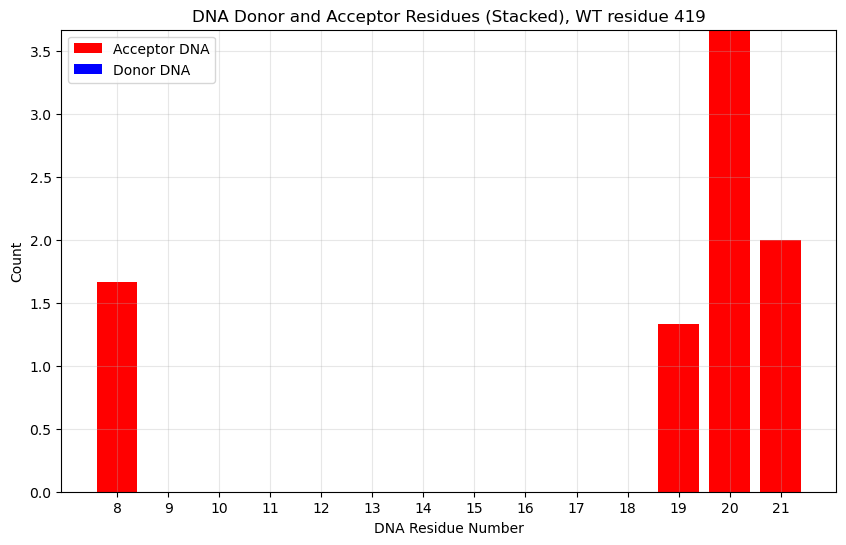

In [626]:
donor_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]
acceptor_wt = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == 419]

donor_counts = donor_wt['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_wt['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) / len(wt_dfs) for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) / len(wt_dfs) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), WT residue 419')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

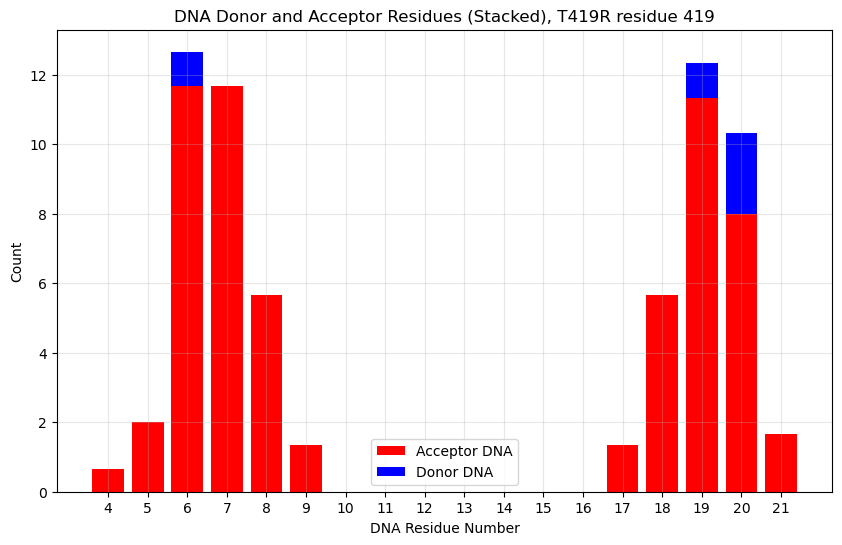

In [631]:
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]

donor_counts = donor_T419R['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_T419R['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) / len(T419R_dfs) for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) / len(T419R_dfs) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), T419R residue 419')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [635]:
def plot_interactions(ax, df_donor, df_acceptor, section, title, replicates):
    # Filter for section
    donor = df_donor[df_donor['acceptor_section'] == section]
    acceptor = df_acceptor[df_acceptor['donor_section'] == section]
    
    # Count occurrences
    donor_counts = donor['acceptor_res_num_adjusted'].value_counts().sort_index()
    acceptor_counts = acceptor['donor_res_num_adjusted'].value_counts().sort_index()
    
    # Get all unique residue numbers
    all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))
    
    # Normalize counts
    donor_values = [donor_counts.get(num, 0) / replicates for num in all_res_nums]
    acceptor_values = [acceptor_counts.get(num, 0) / replicates for num in all_res_nums]
    
    # Create stacked bar plot
    ax.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
    ax.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')
    
    # Set x-ticks
    ax.set_xticks(range(int(min(all_res_nums)), int(max(all_res_nums)) + 1, 1))
    ax.tick_params(axis='x', rotation=45)
    
    # Customize plot
    ax.set_xlabel('DNA Residue Number')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()

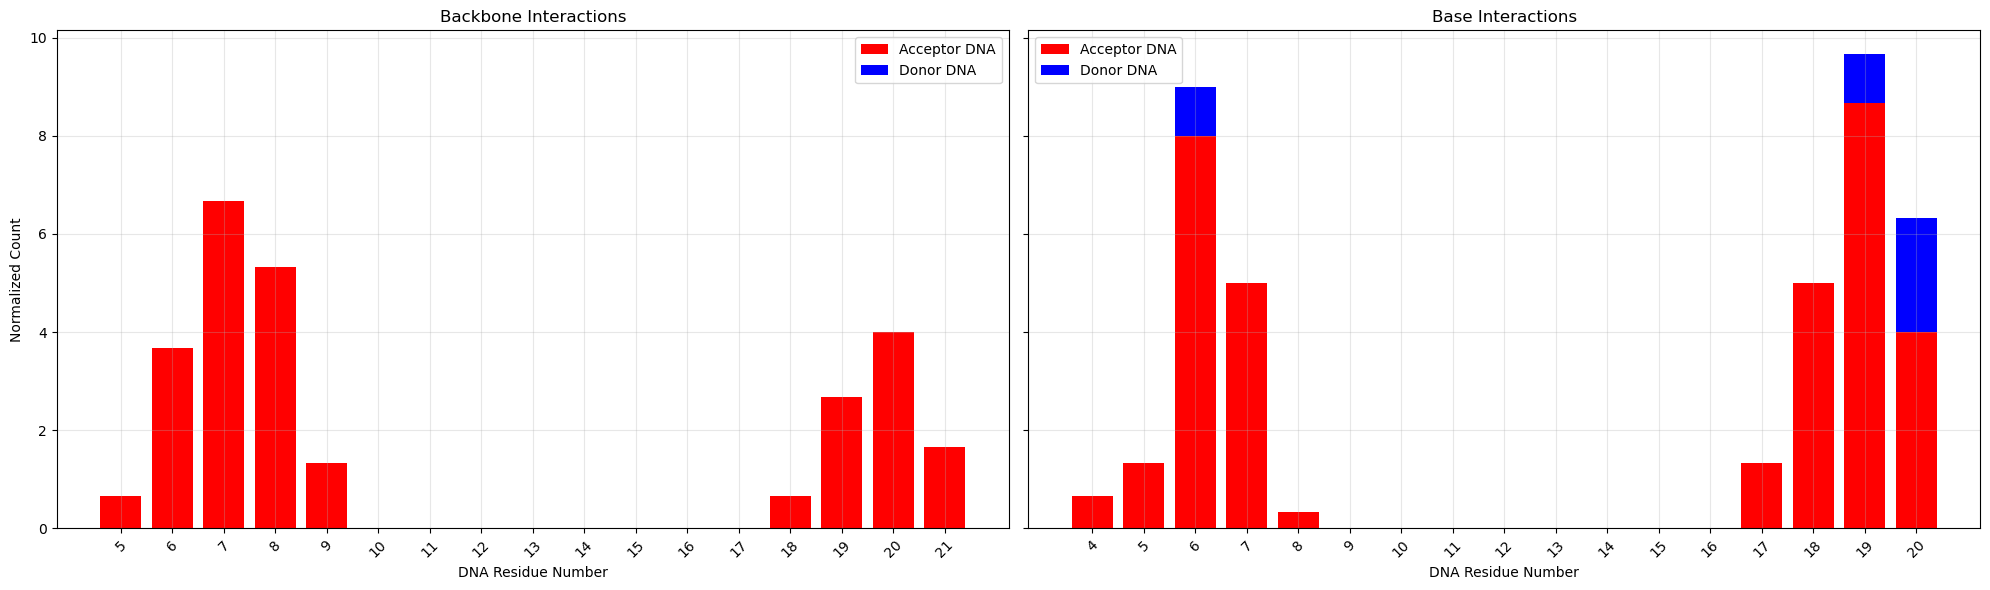

In [636]:
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
ax1.set_ylabel('Normalized Count')  # Update label to reflect normalization

# Plot backbone and base interactions
plot_interactions(ax1, donor_T419R, acceptor_T419R, 'backbone', 'Backbone Interactions', len(T419R_dfs))
plot_interactions(ax2, donor_T419R, acceptor_T419R, 'base', 'Base Interactions', len(T419R_dfs))

# Adjust layout
plt.tight_layout()
plt.show()

### Protein as acceptor

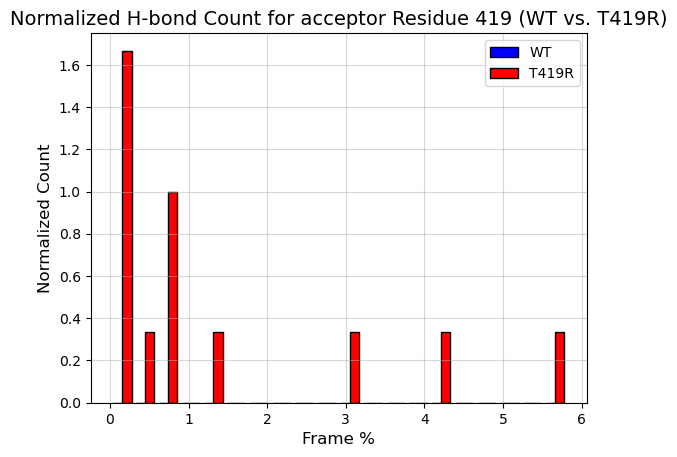

In [638]:
# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == 419]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize WT counts by the number of replicates
normalized_wt_counts = wt_counts / len(wt_dfs)
normalizad_mut_counts = mut_counts / len(T419R_dfs)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
plt.bar(mut_positions, normalizad_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for acceptor Residue 419 (WT vs. T419R)', fontsize=14)  # Updated title
#plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [639]:
filtered_df_T419R.sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
218,20197,20199,4762,59,5.894106,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD
211,20197,20199,4765,42,4.195804,DG,20,N2,D,ARG,284,NH2,A,DNA,protein,20,419,base,DBD
198,19024,19026,4762,31,3.096903,DG,6,N2,C,ARG,284,NH1,A,DNA,protein,6,419,base,DBD
215,19437,19439,14188,15,1.498501,DG,19,N2,C,ARG,284,NH2,B,DNA,protein,19,419,base,DBD
226,20197,20199,4762,9,0.899101,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD
212,19024,19026,4765,9,0.899101,DG,6,N2,C,ARG,284,NH2,A,DNA,protein,6,419,base,DBD
209,20197,20199,4765,8,0.799201,DG,20,N2,D,ARG,284,NH2,A,DNA,protein,20,419,base,DBD
209,20197,20199,4759,6,0.599401,DG,20,N2,D,ARG,284,NE,A,DNA,protein,20,419,base,DBD
204,19024,19026,4762,2,0.199800,DG,6,N2,C,ARG,284,NH1,A,DNA,protein,6,419,base,DBD
208,20197,20199,4759,1,0.099900,DG,20,N2,D,ARG,284,NE,A,DNA,protein,20,419,base,DBD


In [640]:
filtered_df_wt.sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section


WT does not form any hydrogen bonds with residue 419 as the acceptor, while T419R does, albeit with low frame %.

### Statistical test (Mann-Whitney)

In [602]:
from scipy.stats import mannwhitneyu, ttest_ind

In [603]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum().reset_index()
    agg_df['group'] = label
    return agg_df

wt_agg = aggregate_hbonds(wt_dfs_flat, 'wt')
mut_agg = aggregate_hbonds(T419R_dfs_flat, 'T419R')

# Merge WT and MUT aggregated data
all_hbonds = pd.concat([wt_agg, mut_agg])

In [604]:
all_hbonds.head()

,donor,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,count,group
0,3216,19869,327,11,30,wt
1,3216,19870,327,11,553,wt
2,3216,19871,327,11,2,wt
3,3216,19897,327,11,5,wt
4,3216,19899,327,12,195,wt


In [605]:
# Pivot table to compare WT and MUT (unchanged)
pivot_df = all_hbonds.pivot_table(index=['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'], 
                                  columns='group', values='count', fill_value=0)
pivot_df['diff'] = pivot_df['T419R'] - pivot_df['wt']

# Aggregate WT counts across replicates
wt_counts_by_rep = [df.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum() for df in wt_dfs_flat]
wt_counts_df = pd.concat(wt_counts_by_rep, axis=1).fillna(0)
wt_counts_df.columns = [f'rep{i+1}' for i in range(len(wt_dfs_flat))]
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)

# Aggregate MUT counts
mut_counts = mut_agg.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum()

# Create a common index to avoid KeyErrors
common_index = wt_counts_df.index.union(mut_counts.index)

# Reindex both WT and MUT data to the common index
wt_counts_df = wt_counts_df.reindex(common_index, fill_value=0)
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)
mut_counts = mut_counts.reindex(common_index, fill_value=0)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    'WT_mean': wt_mean,
    'WT_std': wt_std,
    'MUT': mut_counts
}).fillna(0)

# Modified compare_groups function to handle missing indices
def compare_groups(row):
    hbond_idx = row.name  # Multi-index tuple
    if hbond_idx in wt_counts_df.index:
        wt_vals = wt_counts_df.loc[hbond_idx].values  # Values across replicates
    else:
        wt_vals = np.zeros(4)  # If hbond not in WT, assume zero counts
    mut_val = row['MUT']
    if np.all(wt_vals == 0) and mut_val == 0:
        return np.nan
    # Use Mann-Whitney U test
    stat, pval = mannwhitneyu(wt_vals, [mut_val] * 4, alternative='two-sided')
    return pval

# Apply statistical test
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences
#significant_diff = comparison_df[comparison_df['p_value'] < 0.05]
significant_diff = comparison_df
print("Significant differences between WT and MUT:")

Significant differences between WT and MUT:


In [606]:
# Apply the compare_groups function to each row
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences (p-value < 0.05)
significant_diff = comparison_df[comparison_df['p_value'] < 0.05]

In [607]:
significant_diff.shape

(389, 4)

In [608]:
significant_diff.head(20)

WT_mean  \
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted               
3216  19889    327                    11                           0.000000   
      19890    327                    11                           0.000000   
      19919    327                    12                           0.000000   
      19920    327                    12                           0.000000   
3231  19889    328                    11                           0.000000   
      19890    328                    11                           0.000000   
      19891    328                    11                           0.000000   
      19900    328                    12                          18.833333   
      19919    328                    12                           0.000000   
      19920    328                    12                           0.000000   
3263  19920    330                    12                           0.000000   
3376  19889    336                    11                           0.000000   
      19890    336                    11                           0.000000   
      19919    336                    12                           0.000000   
      19920    336                    12                           0.000000   
      19966    336                    13                           0.000000   
      19969    336                    13                           0.000000   
      20002    336                    14                           0.000000   
3431  19869    340                    11                         256.500000   
      19870    340                    11                          30.833333   

                                                                     WT_std  \
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted               
3216  19889    327                    11                           0.000000   
      19890    327                    11                           0.000000   
      19919    327                    12                           0.000000   
      19920    327                    12                           0.000000   
3231  19889    328                    11                           0.000000   
      19890    328                    11                           0.000000   
      19891    328                    11                           0.000000   
      19900    328                    12                          14.005951   
      19919    328                    12                           0.000000   
      19920    328                    12                           0.000000   
3263  19920    330                    12                           0.000000   
3376  19889    336                    11                           0.000000   
      19890    336                    11                           0.000000   
      19919    336                    12                           0.000000   
      19920    336                    12                           0.000000   
      19966    336                    13                           0.000000   
      19969    336                    13                           0.000000   
      20002    336                    14                           0.000000   
3431  19869    340                    11                         393.377046   
      19870    340                    11                          21.008728   

                                                                 MUT   p_value  
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted                 
3216  19889    327                    11                          12  0.004040  
      19890    327                    11                           3  0.004040  
      19919    327                    12                          55  0.004040  
      19920    327                    12                          11  0.004040  
3231  19889    328                    11                         203  0.004040  
      19890    328     

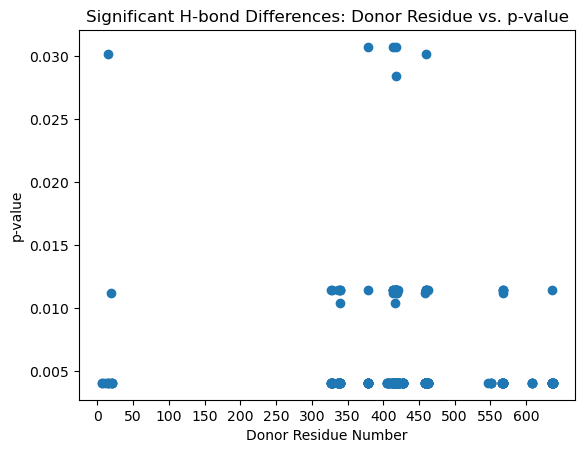

In [609]:
# Extract donor_res_num_adjusted from the multi-index
donor_res_nums = significant_diff.index.get_level_values('donor_res_num_adjusted')

# Plot donor_res_num_adjusted vs p_value
plt.plot(donor_res_nums, significant_diff['p_value'], 'o', label='Significant H-bonds')
# Set x-axis ticks every 5 residues
min_res = donor_res_nums.min()  # Minimum residue number
max_res = donor_res_nums.max()  # Maximum residue number
tick_locations = range(int(min_res // 50) * 50, int(max_res // 50) * 50 + 50, 50)  # Start at a multiple of 5, step by 5
plt.xticks(tick_locations)
plt.xlabel('Donor Residue Number')
plt.ylabel('p-value')
plt.title('Significant H-bond Differences: Donor Residue vs. p-value')
plt.show()

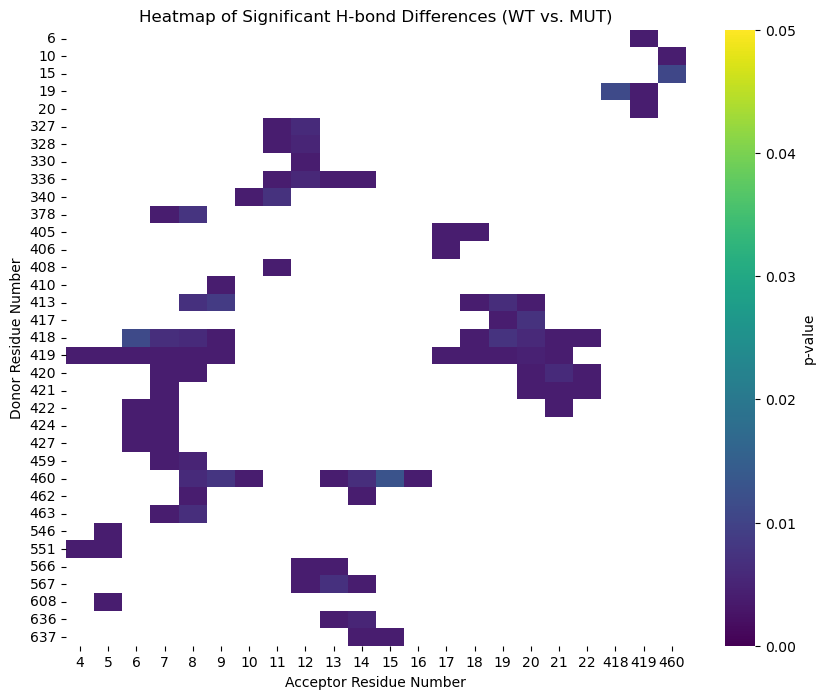

In [610]:
# Reset index to make donor_res_num_adjusted and acceptor_res_num_adjusted columns
significant_diff_reset = significant_diff.reset_index()

# Create a pivot table for the heatmap
heatmap_data = significant_diff_reset.pivot_table(
    index='donor_res_num_adjusted', 
    columns='acceptor_res_num_adjusted', 
    values='p_value', 
    #fill_value=1  # Use 1 (non-significant) for missing values
)

# Plot the heatmap
plt.figure(figsize=(10, 8))  # Adjust size as needed
sns.heatmap(
    heatmap_data, 
    cmap='viridis', 
    vmin=0, vmax=0.05,  # Focus on significant p-values 
    #annot=True, 
    fmt='.3f',  # Format annotations to 3 decimal places
    cbar_kws={'label': 'p-value'}  # Label the color bar
)

# Add labels and title
plt.xlabel('Acceptor Residue Number')
plt.ylabel('Donor Residue Number')
plt.title('Heatmap of Significant H-bond Differences (WT vs. MUT)')
plt.show()

In [611]:
significant_diff_reset[significant_diff_reset['donor_res_num_adjusted'] ==419].sort_values('p_value', ascending=False).head()

,donor,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,WT_mean,WT_std,MUT,p_value
89,4756,20156,419,20,174.666667,190.323584,0,0.011153
86,4746,19034,419,6,0.000000,0.000000,1,0.004040
281,14185,19408,419,18,0.000000,0.000000,2546,0.004040
288,14185,19754,419,6,0.000000,0.000000,81,0.004040
287,14185,19440,419,19,0.000000,0.000000,78,0.004040


In [612]:
combined_df = pd.concat([wt_agg, mut_agg], ignore_index=True)

In [613]:
# Filter for residue 419
residue_419_df = combined_df[
    (combined_df['donor_res_num_adjusted'] == 419) | 
    (combined_df['acceptor_res_num_adjusted'] == 419)
]

In [614]:
# Separate WT and MUT data for residue 419
wt_419 = residue_419_df[residue_419_df['group'] == 'WT']
mut_419 = residue_419_df[residue_419_df['group'] == 'MUT']

# Perform statistical tests
t_stat, t_pval = ttest_ind(wt_419['count'], mut_419['count'], equal_var=False)
u_stat, u_pval = mannwhitneyu(wt_419['count'], mut_419['count'])

print(f"T-test p-value: {t_pval}")
print(f"Mann-Whitney U test p-value: {u_pval}")

T-test p-value: nan
Mann-Whitney U test p-value: nan


/home/irati/miniconda3/envs/thesis_md/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/tmp/ipykernel_1576982/2196208154.py:7: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u_stat, u_pval = mannwhitneyu(wt_419['count'], mut_419['count'])


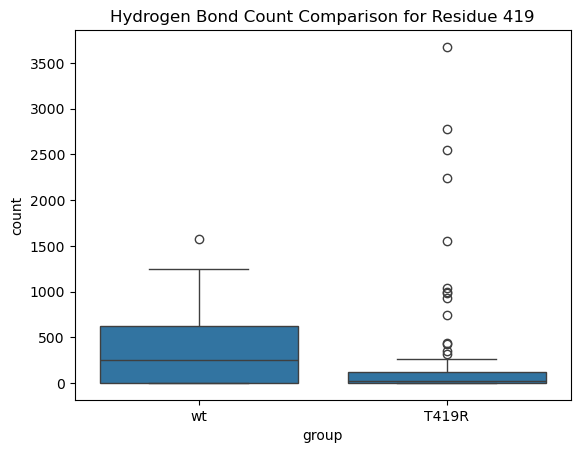

In [615]:
sns.boxplot(data=residue_419_df, x='group', y='count')
plt.title('Hydrogen Bond Count Comparison for Residue 419')
plt.show()